# Ujian Komprehensif

PELATIHAN JARAK JAUH PENGOLAHAN DATA DAN MACHINE LEARNING MENGGUNAKAN PYTHON ANGKATAN II

BALAI PENDIDIKAN DAN PELATIHAN KEUANGAN CIMAHI

18 September 2026


### Identitas

Tulis identitas anda di sini:

Nama : Muhammad Nur Joharis
 
NIP : 198605252006021005

Akun Kaggle : https://www.kaggle.com/code/gajahpenakut/muhammad-nur-joharis-tugas-akhir

### Instruksi

Kerjakan seluruh soal pada notebook ini. 

-------

## Studi Kasus

Bayangkan saat ini Anda berperan sebagai seorang data analyst pada sebuah institusi keuangan “Bank Data”. Anda diminta oleh Direktur Divisi Marketing untuk mengevaluasi efektivitas kampanye telemarketing produk deposito berjangka. Lebih lanjut, Divisi Marketing ingin memprediksi jenis nasabah yang kemungkinan besar akan membuka produk deposito agar tim telemarketing dapat menargetkan kontak dengan lebih efisien pada kampanye selanjutnya. 

### Soal 1
**Business & Data Understanding** (10%)

Jelaskan secara ringkas:

1. Bagaimana kasus tersebut dapat diselesaikan dengan pendekatan machine learning?
2. Jenis dan model algoritma machine learning apa yang paling tepat digunakan untuk menyelesaikan kasus tersebut?


(1.1-2)
Tulis jawaban anda di sini.
1. Pendekatan yang dilakukan:
kasus ini diselesaikan sebagai masalah prediksi kecenderungan nasabah. memanfaatkan data histrori kampanye sebelumnya. lalu kita melatih model agar mempelajari pola karakteristik nasabah yang bersedia membuka deposito. lalu model bisa digunakan untuk memprediksi peluang konversi calon nasabah baru.


3. Jenis Algoritma : Supervised Learning - Binary Classification karena target prediksi terdiri dari dua kategori diskret : membuka deposito (yes) atau tidak (no)
Pilihan model nya : Logistic Regression dan Tree-based Ensemble (Random Forest / Gradient Boosting/ XGBoost)

### Soal 2

**Python for Data Analytics** (10%)

1. Dengan menggunakan pandas:
    - tampilkan lima baris pertama pada dataset yang tersedia. 
    - tampilkan informasi mengenai tipe data dan jumlah _non-missing data_ pada masing-masing kolom. 
2. Buat fungsi dengan nama count_unique() yang menerima nama dataframe dan kolom kemudian  mengembalikan jumlah nilai unik dalam kolom. 
3. Terapkan fungsi tersebut ke seluruh ke seluruh kolom dan simpan hasilnya ke dalam list dengan nama `n_unique_values` (dapat dikerjakan menggunakan perulangan maupun list comprehension).


In [1]:
# (2.1.)
# Tulis jawaban anda di sini
import numpy as np
import pandas as pd
df_train = pd.read_csv("/kaggle/input/competitions/pdml-ii-bdk-cimahi/dataset/train.csv")

display(df_train.head())

df_train.info()

,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,0
1,1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,0
2,2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,0
3,3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,0
4,4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44447 entries, 0 to 44446
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         44447 non-null  int64 
 1   age        44447 non-null  int64 
 2   job        44159 non-null  object
 3   marital    44447 non-null  object
 4   education  42590 non-null  object
 5   default    44447 non-null  object
 6   balance    44447 non-null  int64 
 7   housing    44447 non-null  object
 8   loan       44447 non-null  object
 9   contact    31427 non-null  object
 10  day        44447 non-null  int64 
 11  month      44447 non-null  object
 12  duration   44447 non-null  int64 
 13  campaign   44447 non-null  int64 
 14  pdays      44447 non-null  int64 
 15  previous   44447 non-null  int64 
 16  poutcome   7488 non-null   object
 17  y          44447 non-null  int64 
dtypes: int64(9), object(9)
memory usage: 6.1+ MB


In [3]:
# (2.2.)
# Tulis jawaban anda di sini
def count_unique(dataframe, column_name):
    return dataframe[column_name].nunique()

In [5]:
# (2.3.)
# Tulis jawaban anda di sini
n_unique_values = [count_unique(df_train, col) for col in df_train.columns]

print(dict(zip(df_train.columns, n_unique_values)))

{'id': 44447, 'age': 77, 'job': 11, 'marital': 3, 'education': 3, 'default': 2, 'balance': 7157, 'housing': 2, 'loan': 2, 'contact': 2, 'day': 31, 'month': 12, 'duration': 1568, 'campaign': 48, 'pdays': 547, 'previous': 41, 'poutcome': 3, 'y': 2}


### Soal 3

**Applied Statistics & Exploratory Data Analytics** (25%)

1.  Buat visualisasi yang menggambarkan perbandingan distribusi nilai pada target (y).
2.  Buat visualisasi distribusi data sekurang-kurangnya terhadap 2 variabel numerik.
3.  Buat visualisasi sekurang-kurangnya terhadap 2 variabel kategorial.
4.  Hitung dan tampilkan matriks korelasi antar variabel numerik.
5.  Berdasarkan jawaban pada poin a–d, jelaskan secara ringkas temuan yang akan memengaruhi proses DA selanjutnya.


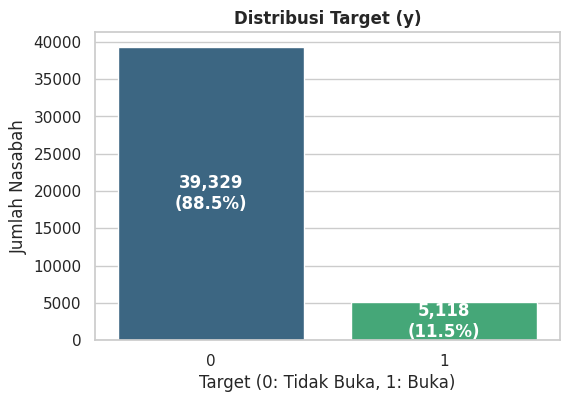

In [12]:
# (3.1.)
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(
    data=df_train, x="y", hue="y", palette="viridis", legend=False, ax=ax
)
ax.set_title("Distribusi Target (y)", fontsize=12, fontweight="bold")
ax.set_xlabel("Target (0: Tidak Buka, 1: Buka)")
ax.set_ylabel("Jumlah Nasabah")

# Menambahkan label jumlah dan persentase di atas bar
total = len(df_train)
for p in ax.patches:
  count = int(p.get_height())
  percentage = f"{100 * count / total:.1f}%"
  ax.annotate(
      f"{count:,}\n({percentage})",
      (p.get_x() + p.get_width() / 2.0, count / 2),
      ha="center",
      va="center",
      color="white",
      fontweight="bold",
  )

plt.show()

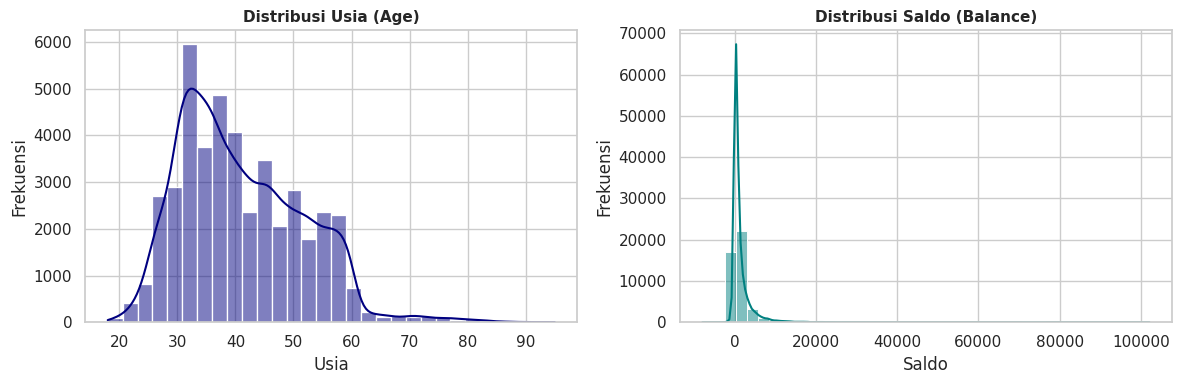

In [13]:
# (3.2.)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1. Distribusi Umur (age)
sns.histplot(data=df_train, x="age", kde=True, bins=30, ax=axes[0], color="navy")
axes[0].set_title("Distribusi Usia (Age)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Usia")
axes[0].set_ylabel("Frekuensi")

# 2. Distribusi Saldo (balance)
sns.histplot(
    data=df_train, x="balance", kde=True, bins=40, ax=axes[1], color="teal"
)
axes[1].set_title("Distribusi Saldo (Balance)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Saldo")
axes[1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

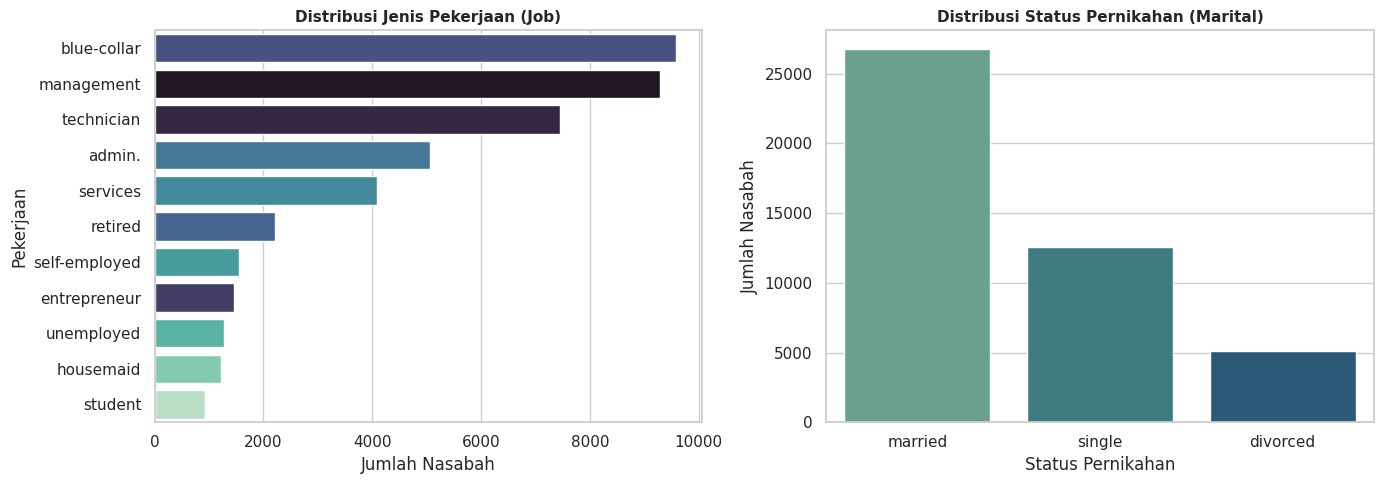

In [15]:
# (3.3.)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribusi Pekerjaan (job)
order_job = df_train["job"].value_counts().index
sns.countplot(
    data=df_train,
    y="job",
    hue="job",
    order=order_job,
    palette="mako",
    legend=False,
    ax=axes[0],
)
axes[0].set_title(
    "Distribusi Jenis Pekerjaan (Job)", fontsize=11, fontweight="bold"
)
axes[0].set_xlabel("Jumlah Nasabah")
axes[0].set_ylabel("Pekerjaan")

# 2. Distribusi Status Pernikahan (marital)
order_marital = df_train["marital"].value_counts().index
sns.countplot(
    data=df_train,
    x="marital",
    hue="marital",
    order=order_marital,
    palette="crest",
    legend=False,
    ax=axes[1],
)
axes[1].set_title(
    "Distribusi Status Pernikahan (Marital)", fontsize=11, fontweight="bold"
)
axes[1].set_xlabel("Status Pernikahan")
axes[1].set_ylabel("Jumlah Nasabah")

plt.tight_layout()
plt.show()

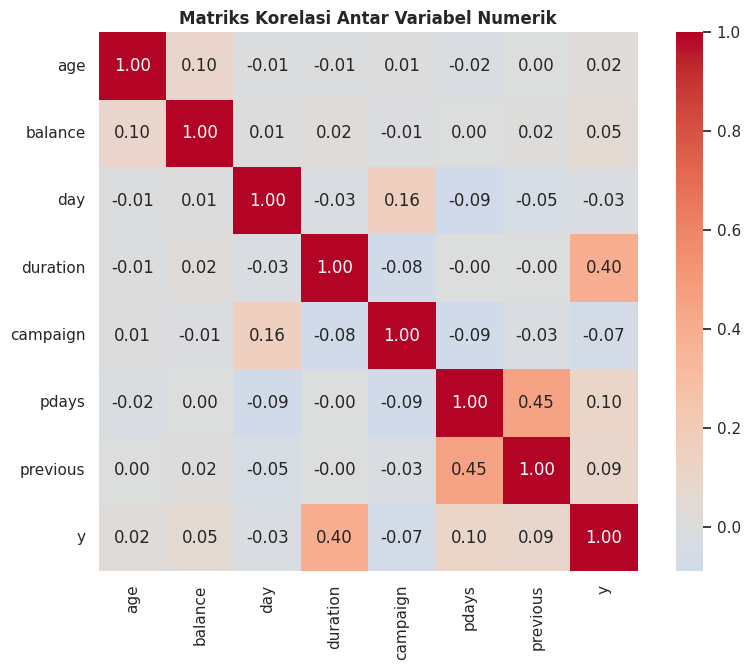

In [16]:
# (3.4.)
# Memilih variabel numerik (mengecualikan 'id')
num_cols = df_train.select_dtypes(include=["int64", "float64"]).columns.drop(
    "id"
)
corr_matrix = df_train[num_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    cbar=True,
)
plt.title(
    "Matriks Korelasi Antar Variabel Numerik", fontsize=12, fontweight="bold"
)
plt.show()

(3.5.)
Tulis jawaban anda di sini

1. **Ketimpangan Kelas (*Class Imbalance*)**:
   Target `y` sangat tidak seimbang (hanya ~11,7% nasabah yang membuka deposito). Akibatnya, metrik *Accuracy* tidak dapat digunakan sebagai tolok ukur performa model karena rentan bias (*accuracy paradox*). Pemodelan memerlukan metrik seperti **ROC-AUC** dan **F1-Score**, serta penyesuaian bobot kelas (*class weight*).

2. **Distribusi Menceng (*Skewness*) dan Nilai Ekstrem (*Outliers*)**:
   Fitur numerik seperti `balance` memiliki sebaran yang sangat menceng ke kanan (*right-skewed*) dengan rentang nilai ekstrem. Model berbasis linear (seperti Logistic Regression) memerlukan standarisasi fitur (*scaling*) agar gradien konvergen dengan baik dan tidak terdistorsi oleh nilai ekstrem.

3. **Konsentrasi Kategori & Kebutuhan Encoding**:
   Fitur kategorial seperti `job` terkonsentrasi pada kelompok *management*, *blue-collar*, dan *technician*, sedangkan `marital` didominasi oleh status *married*. Fitur-fitur kategorial ini harus ditransformasikan ke dalam representasi numerik (*One-Hot Encoding*) agar dapat diproses oleh algoritma *machine learning*.

4. **Korelasi Antar Fitur & Multikolinearitas**:
   Tidak ditemukan korelasi tinggi antar variabel independen ($r < 0{,}8$), sehingga risiko multikolinearitas antar fitur numerik sangat rendah. Fitur dengan korelasi linear tertinggi terhadap target `y` adalah `duration` (durasi panggilan telepon terakhir).

### Soal 4

**Data Preparation** (20%)

1.	Lakukan penanganan terhadap kolom yang memiliki nilai hilang (missing value)! Jelaskan strategi yang dipilih beserta alasannya.
2.	Lakukan ekstraksi fitur sekurang-kurangnya pada 1 data numerik dan 1 data kategorial.
3.	Tambahkan hasil ekstraksi fitur (poin b) ke dalam train.csv.
4.	Susun ulang data train.csv dengan memilih fitur-fitur yang akan digunakan dalam pelatihan model machine learning. Berikan alasan mengapa Anda memilih fitur-fitur tersebut. 


In [17]:
# (4.1.)
# Cek kolom dengan missing values sebelum penanganan
print("Jumlah missing value sebelum penanganan:")
missing_cols = df_train.isnull().sum()
print(missing_cols[missing_cols > 0])

# Imputasi kolom kategorial dengan string 'unknown'
cols_with_na = ['job', 'education', 'contact', 'poutcome']
for col in cols_with_na:
  df_train[col] = df_train[col].fillna('unknown')

print("\nJumlah missing value setelah penanganan:")
print(df_train.isnull().sum().sum())

Jumlah missing value sebelum penanganan:
job            288
education     1857
contact      13020
poutcome     36959
dtype: int64

Jumlah missing value setelah penanganan:
0


In [18]:
# (4.2.)
# 1. Ekstraksi Fitur Numerik: Pengelompokan umur (age_group)
df_train['age_group'] = pd.cut(
    df_train['age'],
    bins=[0, 30, 50, 100],
    labels=['young', 'adult', 'senior'],
    right=False,
)

# 2. Ekstraksi Fitur Kategorial: Ekstraksi kuartal dari bulan kontak (quarter)
month_to_quarter = {
    'jan': 'Q1',
    'feb': 'Q1',
    'mar': 'Q1',
    'apr': 'Q2',
    'may': 'Q2',
    'jun': 'Q2',
    'jul': 'Q3',
    'aug': 'Q3',
    'sep': 'Q3',
    'oct': 'Q4',
    'nov': 'Q4',
    'dec': 'Q4',
}
df_train['quarter'] = df_train['month'].map(month_to_quarter)

# Tampilkan sampel hasil ekstraksi
df_train[['age', 'age_group', 'month', 'quarter']].head()

,age,age_group,month,quarter
0,58,senior,may,Q2
1,44,adult,may,Q2
2,33,adult,may,Q2
3,47,adult,may,Q2
4,33,adult,may,Q2


In [19]:
# (4.3.)
# Menampilkan 5 baris pertama dengan kolom baru yang sudah terintegrasi
print(f"Dimensi dataset saat ini: {df_train.shape}")
display(df_train[['id', 'age_group', 'quarter', 'y']].head())

Dimensi dataset saat ini: (44447, 20)


,id,age_group,quarter,y
0,0,senior,Q2,0
1,1,adult,Q2,0
2,2,adult,Q2,0
3,3,adult,Q2,0
4,4,adult,Q2,0


In [20]:
# (4.4.)
# 1. Drop identifier unik yang tidak relevan untuk prediksi
df_ready = df_train.drop(columns=['id'])

# 2. Pisahkan fitur (X) dan target (y)
X = df_ready.drop(columns=['y'])
y = df_ready['y']

# 3. Lakukan One-Hot Encoding pada seluruh variabel kategorial
X_encoded = pd.get_dummies(X, drop_first=True)

print(
    f"Dimensi fitur setelah encoding: {X_encoded.shape} (Baris: {X_encoded.shape[0]}, Fitur: {X_encoded.shape[1]})"
)
print(f"Dimensi target: {y.shape}")
X_encoded.head()

Dimensi fitur setelah encoding: (44447, 47) (Baris: 44447, Fitur: 47)
Dimensi target: (44447,)


,age,balance,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown,age_group_adult,age_group_senior,quarter_Q2,quarter_Q3,quarter_Q4
0,58,2143,5,261,1,-1,0,False,False,False,...,False,False,False,False,True,False,True,True,False,False
1,44,29,5,151,1,-1,0,False,False,False,...,False,False,False,False,True,True,False,True,False,False
2,33,2,5,76,1,-1,0,False,True,False,...,False,False,False,False,True,True,False,True,False,False
3,47,1506,5,92,1,-1,0,True,False,False,...,False,False,False,False,True,True,False,True,False,False
4,33,1,5,198,1,-1,0,False,False,False,...,False,False,False,False,True,True,False,True,False,False


#### 1. Strategi Penanganan Missing Value (4.1):
* **Strategi**: Mengisi (*impute*) nilai yang hilang pada fitur kategorial (`job`, `education`, `contact`, `poutcome`) dengan kategori baru, yaitu `'unknown'`.
* **Alasan**:
  * Pada data pemasaran perbankan, ketiadaan data sering kali membawa informasi tersendiri (*Missing Not at Random* / MNAR). Misalnya pada `poutcome`, nilai kosong mencapai ~83% karena nasabah memang belum pernah dihubungi pada kampanye sebelumnya.
  * Menghapus baris (*dropping rows*) akan membuang sebagian besar observasi data secara sia-sia. Sedangkan menggantinya dengan modus (*mode imputation*) akan mendistorsi distribusi data asli secara signifikan. Kategori `'unknown'` mempertahankan seluruh data tanpa menimbulkan bias distribusi buatan.

#### 2. Alasan Pemilihan & Penyusunan Fitur (4.4):
* **Penyisihan Kolom Identitas**: Kolom `id` dihapus dari data latih karena hanya berfungsi sebagai *identifier* unik dan tidak memiliki nilai prediktif. Mempertahankannya berisiko menyebabkan model menghafal urutan data (*overfitting*).
* **Retensi Fitur Prediktor**: Seluruh karakteristik demografi nasabah (`age`, `job`, `marital`, `education`), profil finansial (`balance`, `housing`, `loan`), serta riwayat kampanye (`duration`, `campaign`, `pdays`, `previous`, `poutcome`) dipertahankan karena secara bisnis berpengaruh langsung terhadap keputusan pembukaan deposito.
* **Integrasi Fitur Ekstraksi**: Fitur baru `age_group` dan `quarter` disertakan untuk membantu model menangkap pola non-linear dari segmentasi usia dan tren musiman kuartal promosi.
* **One-Hot Encoding**: Semua fitur kategorial diubah menjadi variabel biner menggunakan `pd.get_dummies(drop_first=True)` untuk menghindari *dummy variable trap* dan memastikan format data siap dikomputasi oleh model linear maupun *tree-based*.

### Soal 5

**Machine Learning** (25%)

1.	Latih sekurang-kurangnya 2 model algoritma berbeda untuk memprediksi y menggunakan seluruh/sebagian feature pada train.csv yang telah dimodifikasi dari soal sebelumnya.
2.	Evaluasi performa kedua model menggunakan metrik yang sesuai. Jelaskan alasan Anda memilih metrik tersebut.
3.	Lakukan setidaknya upaya Feature Selection/Hyperparameter Tuning pada model terbaik kemudian bandingkan performanya performa sebelum dan sesudah tuning.


In [21]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Split data (80% train, 20% validation) dengan stratify agar proporsi target seimbang
X_train, X_val, y_train, y_val = train_test_split(
    X_encoded.astype(float),
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

# 2. Inisialisasi Model 1: Logistic Regression (menggunakan Pipeline + StandardScaler)
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    (
        'lr',
        LogisticRegression(
            class_weight='balanced', max_iter=1000, random_state=42
        ),
    ),
])

# 3. Inisialisasi Model 2: Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1
)

# 4. Latih kedua model
print("Melatih Logistic Regression...")
pipe_lr.fit(X_train, y_train)

print("Melatih Random Forest...")
rf_model.fit(X_train, y_train)


# 5. Evaluasi kedua model
def evaluate_model(model, X, y_true):
  y_pred = model.predict(X)
  y_proba = model.predict_proba(X)[:, 1]
  return {
      'ROC-AUC': roc_auc_score(y_true, y_proba),
      'F1-Score': f1_score(y_true, y_pred),
      'Precision': precision_score(y_true, y_pred),
      'Recall': recall_score(y_true, y_pred),
  }


results = {
    'Logistic Regression': evaluate_model(pipe_lr, X_val, y_val),
    'Random Forest': evaluate_model(rf_model, X_val, y_val),
}

df_eval = pd.DataFrame(results).T
display(df_eval.round(4))

Melatih Logistic Regression...
Melatih Random Forest...


,ROC-AUC,F1-Score,Precision,Recall
Logistic Regression,0.9130,0.5541,0.4175,0.8232
Random Forest,0.9323,0.4264,0.6847,0.3096


### Alasan Pemilihan Metrik Evaluasi (Soal 5.2):

Evaluasi performa model menggunakan metrik **ROC-AUC** dan **F1-Score** (didukung oleh *Precision* dan *Recall*), dengan alasan:

1. **ROC-AUC (*Receiver Operating Characteristic - Area Under Curve*)**:
   * Mengukur kemampuan model dalam meranking dan membedakan nasabah potensial (kelas 1) dari nasabah tidak potensial (kelas 0) di berbagai tingkat ambang batas probabilitas (*classification threshold*).
   * Nilai ROC-AUC bersifat independen terhadap proporsi kelas sehingga menjadi metrik paling objektif untuk dataset yang *imbalanced*.

2. **F1-Score (*Harmonic Mean of Precision & Recall*)**:
   * Mengukur titik temu terbaik antara **Precision** (memastikan tim pemasaran tidak membuang waktu dan biaya menghubungi nasabah yang tidak tertarik) dan **Recall** (memastikan sesedikit mungkin nasabah pembuka deposito yang terlewatkan).
   * F1-Score memfokuskan evaluasi pada kelas minoritas (`y = 1`), berbeda dengan *Accuracy* yang nilainya dapat terlihat tinggi secara semu meski model gagal memprediksi kelas minoritas.

In [22]:
from sklearn.model_selection import GridSearchCV

# 1. Definisikan parameter grid untuk Random Forest
param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [10, 15, 20],
    'min_samples_split': [5, 10],
}

# 2. Grid Search dengan 3-Fold Cross Validation
print("Memulai Hyperparameter Tuning...")
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        class_weight='balanced', random_state=42, n_jobs=-1
    ),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3,
    verbose=1,
    n_jobs=-1,
)

grid_search.fit(X_train, y_train)
best_rf_model = grid_search.best_estimator_

print(f"\nParameter Terbaik: {grid_search.best_params_}")

# 3. Bandingkan performa sebelum vs sesudah tuning pada data validasi
eval_before = evaluate_model(rf_model, X_val, y_val)
eval_after = evaluate_model(best_rf_model, X_val, y_val)

comparison_df = pd.DataFrame(
    {'Sebelum Tuning (Baseline)': eval_before, 'Setelah Tuning': eval_after}
).T

print("\nPerbandingan Performa Model:")
display(comparison_df.round(4))

Memulai Hyperparameter Tuning...
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Parameter Terbaik: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 150}

Perbandingan Performa Model:


,ROC-AUC,F1-Score,Precision,Recall
Sebelum Tuning (Baseline),0.9323,0.4264,0.6847,0.3096
Setelah Tuning,0.9337,0.6004,0.5751,0.6279


In [26]:
# 1. Muat dataset test
df_test = pd.read_csv(
    "/kaggle/input/competitions/pdml-ii-bdk-cimahi/dataset/test.csv"
)

# 2. Tangani missing value dengan kategori 'unknown' (sama seperti train)
cols_with_na = ["job", "education", "contact", "poutcome"]
for col in cols_with_na:
  df_test[col] = df_test[col].fillna("unknown")

# 3. Ekstraksi fitur yang sama persis
df_test["age_group"] = pd.cut(
    df_test["age"],
    bins=[0, 30, 50, 100],
    labels=["young", "adult", "senior"],
    right=False,
)
df_test["quarter"] = df_test["month"].map(month_to_quarter)

# 4. One-Hot Encoding & Penyelarasan Kolom agar identik dengan data train
X_test = df_test.drop(columns=["id"])
X_test_encoded = pd.get_dummies(X_test, drop_first=True)
X_test_encoded = X_test_encoded.reindex(
    columns=X_encoded.columns, fill_value=0
).astype(float)

# 5. Prediksi nilai probabilitas kelas 1 (desimal 0.0 - 1.0)
test_preds = best_rf_model.predict(X_test_encoded)

# 6. Simpan hasil ke submission.csv
submission = pd.DataFrame({"id": df_test["id"], "y": test_preds})
submission.to_csv("submission.csv", index=False)

print("File submission.csv biner berhasil dibuat kembali!")
display(submission.head())
print("\nDistribusi prediksi:")
print(submission["y"].value_counts())

File submission.csv biner berhasil dibuat kembali!


,id,y
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0



Distribusi prediksi:
y
0    3900
1     621
Name: count, dtype: int64
